In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, auc, roc_auc_score, roc_curve

from tqdm.auto import tqdm
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

In [2]:
# load data
df = pd.read_csv('/workspaces/ML-Zoomcamp/Module 03-classification/course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
# Fill missing values

categorical = [
        'lead_source', 'industry', 'employment_status', 'location'
       ]

numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score']

for col in categorical:
    df[col] = df[col].fillna('NA')

for col in numerical:
    df[col] = df[col].fillna(0.0)

In [5]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [6]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

# reset the index
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# target variable
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [7]:

for col in numerical:
    score = df_train[col]
    auc_value = roc_auc_score(y_train, score)

    if auc_value < 0.5:
        auc_value = roc_auc_score(y_train, -score)

    print(f'{col}: {auc_value:.3f}')

annual_income: 0.602
number_of_courses_viewed: 0.720
interaction_count: 0.767
lead_score: 0.788


**Q2**

In [8]:

dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred_val = model.predict_proba(X_val)[:, 1]

In [9]:
converted_decision = (y_pred_val >= 0.50)
print((y_val == converted_decision).mean())

0.645


**Q3**

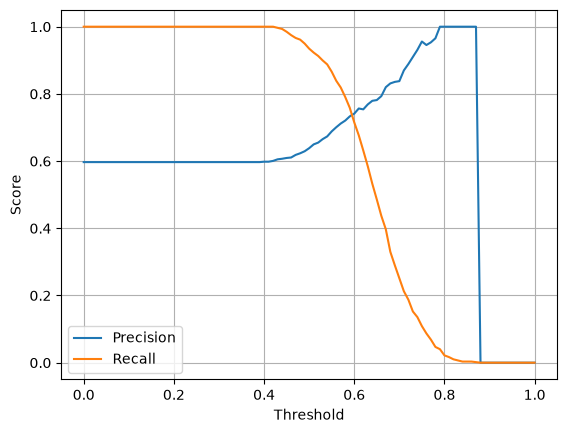

In [10]:
thresholds = np.arange(0.0, 1.01, 0.01)
precisions = []
recalls = []

for threshold in thresholds:
    y_pred = y_pred_val >= threshold
    tp = np.sum((y_pred == 1) & (y_val == 1))
    fp = np.sum((y_pred == 1) & (y_val == 0))
    fn = np.sum((y_pred == 0) & (y_val == 1))
    
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    precisions.append(precision)
    recalls.append(recall)

plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid(True)
plt.show()


**Q4**

In [11]:
thresholds = np.arange(0.0, 1.01, 0.01)
f1_scores = []

for threshold in thresholds:
    y_pred = y_pred_val >= threshold

    tp = np.sum((y_pred == 1) & (y_val == 1))
    fp = np.sum((y_pred == 1) & (y_val == 0))
    fn = np.sum((y_pred == 0) & (y_val == 1))

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

    f1_scores.append(f1)

best_idx = np.argmax(f1_scores)
print(f'Maximum F1: {f1_scores[best_idx]:.3f} at threshold {thresholds[best_idx]:.2f}')

Maximum F1: 0.767 at threshold 0.55


In [12]:
for threshold in [0.21, 0.41, 0.61, 0.81]:
    y_pred = y_pred_val >= threshold

    tp = np.sum((y_pred == 1) & (y_val == 1))
    fp = np.sum((y_pred == 1) & (y_val == 0))
    fn = np.sum((y_pred == 0) & (y_val == 1))

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

    print(f"threshold={threshold:.2f}, F1={f1:.3f}")

threshold=0.21, F1=0.748
threshold=0.41, F1=0.749
threshold=0.61, F1=0.714
threshold=0.81, F1=0.033


**Q5**

In [13]:

def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver = 'liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred_val = model.predict_proba(X)[:, 1]

    return y_pred_val


In [14]:
kfold = KFold(n_splits= 5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train, C = 1.0)
    y_pred_val = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred_val)
    scores.append(auc)

print(' %.3f +- %.3f' % ( np.mean(scores), np.std(scores)))

 0.731 +- 0.012


**Q6**

In [15]:

n_splits = 5

for C in tqdm([0.000001, 0.001, 1]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred_val = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred_val)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/3 [00:00<?, ?it/s]

C=1e-06 0.616 +- 0.010
C=0.001 0.744 +- 0.013
C=1 0.731 +- 0.012
